# A system of ODEs: Method 2 - using RK4 in array form

In [4]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina' # hig-res plots for a Retina display

## A predator-prey relationship for Rabbits and Foxes

The predator-prey relationship is a classic coupled ODE system. Here we describe the coupled population dynamics of rabbits, $R$, and foxes, $F$, with the following:

\begin{align}
\frac{dR}{dt} &= aR-bRF \\
\frac{dF}{dt} &= -lF+kRF 
\end{align}

where $R$ and $F$ are the population values of rabbits and foxes. The coefficients are defined as:

\begin{align}
a &= \text{base birth rate of rabits}  \\
b &= \text{prey factor}  \\
l &= \text{fox base diminishing rate}\\
k &= \text{feeding rate}
\end{align}

This coupled system of equations is solved below using 4th-order Runge-Kutta and arrays.

## Method 2: write out the Runge-Kutta coefficient once and use arrays

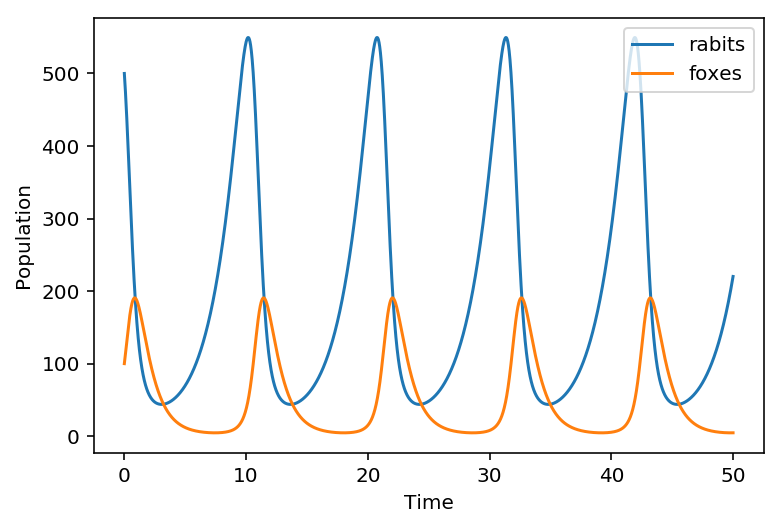

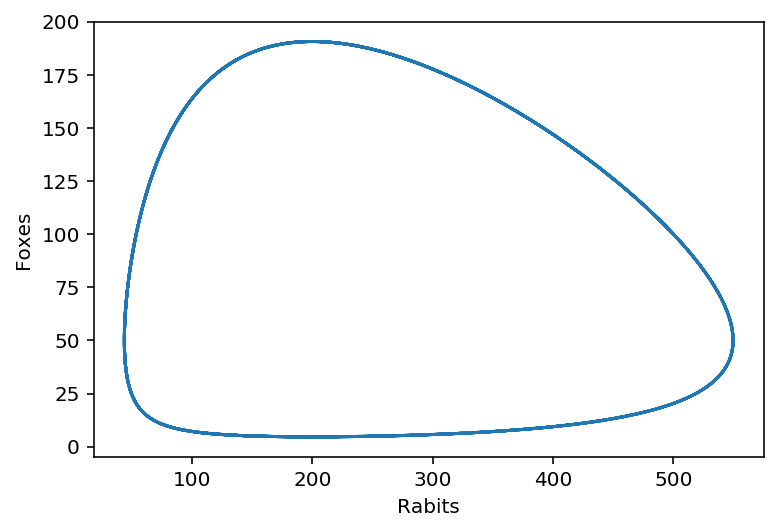

In [7]:
# --- User input ------------

# define the functions dy/dx = f(x,y)
def f(t,y):
    # R = y[0] and F = y[1]
    return np.array([a*y[0]-b*y[0]*y[1],
                 -l*y[1]+k*y[0]*y[1]])

# define the number of points and the start and stop locations
start = 0
end = 50
dt = 0.01
R_0 = 500
F_0 = 100

# define the coefficients
a = 0.5   # base birth rate of rabits
b = 0.01 # pray factor
l = 1      # fox base diminishing rate
k = 0.005  # feeding rate

# --- Calculations ------------

# setup the x and y arrays
t = np.arange(start,end,dt)
N = len(t)
y = np.zeros(shape=(2,N))

# set the initial condition
y[:,0]=[R_0,F_0]

# 4th Order Runge Kutta loop 
for i in range(0,N-1):
    K1 = f(t[i]          , y[:,i]             )
    K2 = f(t[i]+0.5*dt, y[:,i]+0.5*dt*K1)
    K3 = f(t[i]+0.5*dt, y[:,i]+0.5*dt*K2)
    K4 = f(t[i]+    dt, y[:,i]+    dt*K3)
    y[:,i+1] = y[:,i]+(dt/6)*(K1+2*K2+2*K3+K4)
    
# --- plot the results ------------

fig, ax = plt.subplots()
ax.plot(t,y[0,:], label='rabits')
ax.plot(t,y[1,:], label='foxes')
ax.set_xlabel('Time')
ax.set_ylabel('Population')
plt.legend(loc=1);

fig, ax = plt.subplots()
ax.plot(y[0,:],y[1,:])
ax.set_xlabel('Rabits')
ax.set_ylabel('Foxes');